In [1]:
import numpy as np
import matplotlib.pyplot as plt
from stl import Mesh
from base import iterative_section_minimiser
from base.utils import rotate

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# read the mesh file and its adjacent triangles. 
mesh_data = Mesh.from_file("./data/cylinder_mesh/straight_cylinder_L10_R1.stl")

In [3]:
def compare_analytical(n):
    
    n_norm = n /  np.linalg.norm(n)
    
    a = iterative_section_minimiser.section_area(1, n_norm)
    W = iterative_section_minimiser.analytical_W(1, n_norm)

    _,_,_, W2, a2, _ = iterative_section_minimiser.mesh_intersect(mesh_data, [0,0,0], n_norm)

    return a, a2, W, W2


In [4]:
# test the minimiser against the analytical solution for a cylinder of radius 1, in the x direction. 
test_normals = np.zeros((10, 3))

test_normals[:, 0] = np.ones(10)
test_normals[:, 1] = np.linspace(0.1, 3.0, 10)

thetai = [elem[0] / np.linalg.norm(elem) for elem in test_normals]
test_outputs = [compare_analytical(n) for n in test_normals]


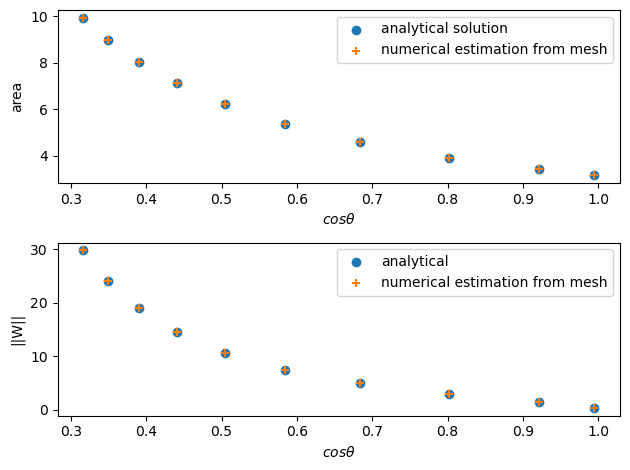

In [5]:
fig, axes = plt.subplots(2, 1)

axes[0].scatter(thetai, [elem[0] for elem in  test_outputs], label = "analytical solution")
axes[0].scatter(thetai, [elem[1] for elem in  test_outputs], label = "numerical estimation from mesh", marker = "+")
axes[0].set_ylabel("area")
axes[0].set_xlabel("$cos\\theta$")

axes[1].scatter(thetai, [np.linalg.norm(elem[2]) for elem in  test_outputs], label = "analytical")
axes[1].scatter(thetai, [np.linalg.norm(elem[3]) for elem in  test_outputs], label = "numerical estimation from mesh", marker = "+")
axes[1].set_ylabel("||W||")
axes[1].set_xlabel("$cos\\theta$")

for ax in axes: 
    ax.legend()

plt.tight_layout()
plt.show()


In [9]:
# read the mesh file and its adjacent triangles. 
conduit_type = "extra_sinuous_D5_r_1"
#conduit_type = "straight_cylinder_L8_R1_stochastic"
mesh_data = Mesh.from_file(f"data/cylinder_mesh/{conduit_type}.stl")

P0 = np.array([-5, 0.1, 0])
P_end = np.array([5, -0.1, 0])
nP0 = np.array([0, 1, 0])
L = 5
ds = 0.25
verbose = True


In [10]:
result = iterative_section_minimiser.iterative_pathfinder(mesh_data, P0, P_end, nP0, verbose = False, ds=ds, minimise_strategy="dumb")

40.0
centre of gravity of best section [-4.99458673e+00  1.00000001e-01 -1.28234971e-03]
centre of gravity of best section [-4.99145402e+00  3.49999994e-01  3.47743784e-03]
centre of gravity of best section [-4.97835588e+00  6.00000024e-01  3.06166712e-03]
centre of gravity of best section [-4.93064804e+00  8.58039334e-01 -1.79736723e-03]
centre of gravity of best section [-4.93987201  1.09908833 -0.00880756]
centre of gravity of best section [0.03938717 0.21033885 0.01579665]
centre of gravity of best section [-0.01703559  0.44525791 -0.01225982]
centre of gravity of best section [-0.04120249  0.69413503 -0.00917267]
centre of gravity of best section [-3.11418398e-02  9.45666656e-01 -3.35534672e-04]
centre of gravity of best section [-0.07859936  1.19273876  0.00638175]
centre of gravity of best section [-0.13687984  1.43490208 -0.0183028 ]
centre of gravity of best section [-0.1725831   1.68250417 -0.01560739]
centre of gravity of best section [-2.06060096e-01  1.93054080e+00  6.0315

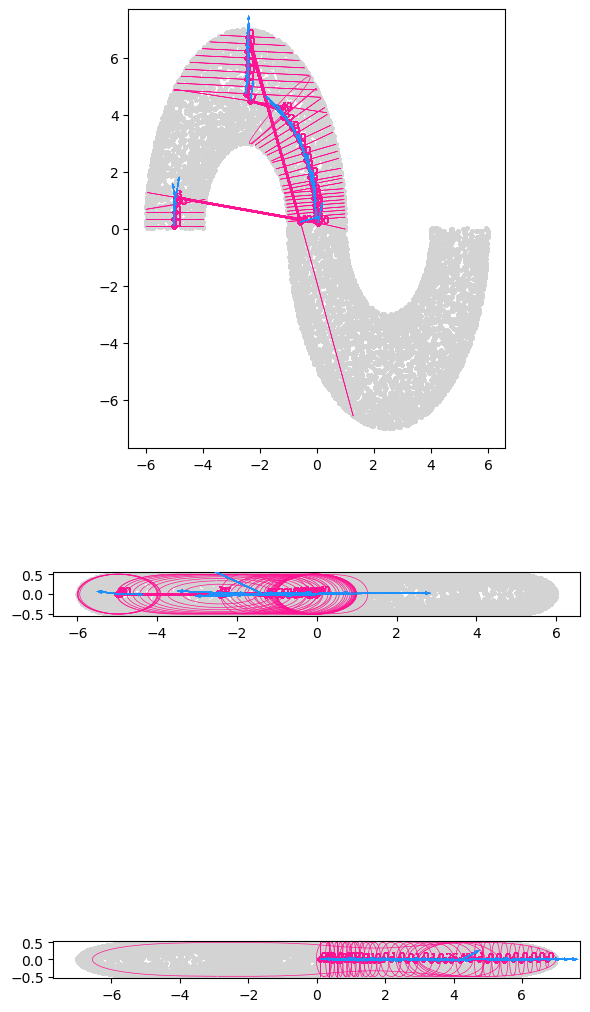

In [11]:
fig, axes = plt.subplots(3, 1, figsize = (6, 12))

for viewpoint, ax in zip([[0,1],[0,2], [1,2]], axes):
    for c, step in enumerate(result["vertices"]):
        ax.plot(*step[:, viewpoint].T, color = "deeppink", lw = 0.5)

        # plot the point cloud
        ax.scatter(*mesh_data[::50, viewpoint].T,
                   color = "lightgrey",
                   alpha = 0.5, 
                   s=2)

        # plot the centreline
        ax.plot(*result["centreline"][:, viewpoint].T, 
                "-o", 
                markersize =3, 
                color = "deeppink", 
                zorder = 10)
        
        
        # plot the centreline
        for c, elem in enumerate(result["centreline"][:-1]):

            ax.text(*elem[viewpoint],
                    result["n_iterations"][c], 
                    fontsize =7, 
                    color = "deeppink", 
                    zorder = 10)
        
        # plot the vector normals
        
        ax.quiver(*result["centreline"][:-1, viewpoint].T, 
                  *result["normals"][:, viewpoint].T, 
                  color ="dodgerblue",
                  width = 0.002, 
                  zorder = 100)

        ax.set_aspect("equal")

plt.tight_layout()
plt.savefig(f"temp/IterativeCentreline_{conduit_type}_plot.png", dpi = 300)